# 과제 1 — 시연 데이터 수집 및 Hub 업로드

**과제 내용**: 본인이 선택한 태스크(예: "큐브 집어 상자에 넣기")에 대해 **성공한 시연 50 에피소드**를 수집하고 Huggingface Hub에 업로드한다. 업로드 후 모든 에피소드를 검수해 문제가 없음을 확인한다.

### 작성 요령
- 이 노트북을 본인 GitHub 저장소(assignments 폴더)에 `assignment_1.ipynb`로 올리고 저장소 링크를 제출한다. (이후 모든 과제도 동일하게 제출 예정)
- 데이터 수집은 **터미널에서** `lerobot-record`로 진행하고 이 노트북에는 확인 코드와 검수 결과를 작성한다.
- 모든 코드 셀은 **실행한 뒤 출력 결과가 보이는 상태로** 커밋한다. (출력이 없으면 미제출로 간주)
- `[작성]` 표시가 있는 부분을 모두 채운다.

### 주의 사항
- 데이터셋은 **public**으로 업로드한다. (private이면 웹 뷰어와 채점 코드로 확인할 수 없음)
- 데이터셋 이름은 자유롭게 정하되, **0. 제출 정보 셀**에 적은 repo_id **하나만** 채점 대상으로 한다.
- 실패한 시연, 중간에 잘린 시연, 카메라 영상이 비정상인 시연은 **다시 녹화**한다. 이 데이터는 이후 과제 학습에 그대로 쓰이며, ACT는 시연을 그대로 모방하므로 나쁜 시연은 성공률을 직접 떨어뜨린다.
- `--dataset.single_task`에 넣는 태스크 문장은 **영어로** 쓴다. (예: "Pick up the cube and put it in the box.") 과제 5에서 학습할 SmolVLA는 이 문장을 언어 입력으로 받는데, SmolVLA의 언어 모델은 영어로 학습되었다.
- GitHub 저장소에는 데이터 파일을 올리지 않는다. (데이터는 Huggingface Hub에 올리고 노트북 파일만 올린다.)
- **마감 시각 이후의 커밋은 반영하지 않는다.**

## 0. 제출 정보

In [3]:
# 제출 정보
STUDENT_ID = "2021136087"
NAME = "윤희건"
HF_USER = "yhks"

DATASET = f"{HF_USER}/my_task"   # 업로드한 데이터셋 repo_id
TASK = "Grab the black cube"   # 녹화 시 --dataset.single_task에 넣은 영어 문장 그대로

print("학번/이름      :", STUDENT_ID, NAME)
print("데이터셋 repo_id:", DATASET)
print("데이터셋 링크  :", f"https://huggingface.co/datasets/{DATASET}")
print("태스크 설명    :", TASK)
REVISION = "9837af86d698eb2408a58255dd152ff7d1ef36a6"
print("검수 커밋      :", REVISION)
print("커밋 링크      :", f"https://huggingface.co/datasets/{DATASET}/commit/{REVISION}")


학번/이름      : 2021136087 윤희건
데이터셋 repo_id: yhks/my_task
데이터셋 링크  : https://huggingface.co/datasets/yhks/my_task
태스크 설명    : Grab the black cube
검수 커밋      : 9837af86d698eb2408a58255dd152ff7d1ef36a6
커밋 링크      : https://huggingface.co/datasets/yhks/my_task/commit/9837af86d698eb2408a58255dd152ff7d1ef36a6


In [4]:
# Hub 접근 확인 — "OK"가 나와야 한다
import json
import pandas as pd
import matplotlib.pyplot as plt
from huggingface_hub import HfApi, hf_hub_download

from pathlib import Path
CACHE_DIR = Path.cwd() / "work" / "hf_cache"
CACHE_DIR.mkdir(parents=True, exist_ok=True)
_original_download = hf_hub_download
def hf_hub_download(repo_id, filename, **kwargs):
    return _original_download(repo_id, filename, revision=REVISION, cache_dir=CACHE_DIR, **kwargs)
api = HfApi()
repo_info = api.dataset_info(DATASET, revision=REVISION, token=False)
print("공개 여부:", not repo_info.private)
assert not repo_info.private
try:
    repo_files = api.list_repo_files(DATASET, repo_type="dataset", revision=REVISION, token=False)
    print(f"OK  {DATASET}  (파일 {len(repo_files)}개)")
except Exception as e:
    repo_files = []
    print(f"FAIL  {DATASET} -> {type(e).__name__}: public 여부와 repo_id를 확인할 것")

공개 여부: True
OK  yhks/my_task  (파일 11개)


## 1. 태스크 및 수집 환경

### 1-1. 태스크 정의
- **태스크 설명**: 본드 용기와 젤콤 종이박스를 그리퍼로 잡아 빈 박스에 넣고 다시 꺼내는 작업을 태스크로 정했다.
- **미션 목표**: 물체의 위치와 방향이 달라지거나 주변 물체 때문에 공간과 시야가 제한되는 상황에서도 작업을 이어갈 수 있도록 시연 데이터를 수집하는 것을 목표로 했다.
- **수집 시나리오**: 본드와 젤콤 종이박스를 모두 넣고 꺼내는 경우, 둘 중 하나만 넣고 꺼내는 경우, 두 물체가 이미 박스 안에 있는 상태에서 밖으로 꺼내는 경우, 한 개씩 꺼내는 경우로 나누어 촬영했다. 이 시나리오들을 그리퍼 각도를 세로로 한 자세에서도 수행하도록 에피소드를 구성했다.
- **성공 조건**: 각 에피소드에서 정한 시나리오에 따라 대상 물체를 잡아 박스에 넣거나 박스 밖으로 꺼내는 동작을 완료하는 것으로 정했다.

### 1-2. 수집 환경
- 로봇: SO-101 leader(`leader1`)를 직접 조작해 follower(`follower1`)를 움직이며 시연을 녹화했다.
- 연결: follower `/dev/so101_follower`, leader `/dev/so101_leader`.
- 카메라: 2개, overhead(장치 4)와 wrist(장치 6), RGB 640×480.
- 카메라는 고정 시점의 overhead와 그리퍼 근처 시점의 wrist를 함께 사용해 로봇 동작과 물체 주변을 기록했다.
- 녹화 명령에서 카메라 fps는 25로 설정했다. 저장된 데이터셋과 MP4의 fps는 30으로 확인되어 에피소드 길이는 30 fps를 기준으로 계산했다.
- 물체 배치 방식: 시나리오에 따라 본드와 젤콤 종이박스를 박스 밖에 놓거나, 두 물체를 모두 박스 안에 둔 상태에서 녹화를 시작했다.
- 저장: LeRobot v3.0, 50개 에피소드, 44,947프레임, state/action 각 6차원. 각 에피소드는 898~899프레임(약 29.93~29.97초)이다.

### 1-3. 실제 녹화 명령어

아래 명령으로 에피소드당 녹화 시간 30초, 환경 초기화 시간 15초를 설정해 50개 에피소드를 수집했다.

```bash
lerobot-record \
  --robot.type=so101_follower \
  --robot.port=/dev/so101_follower \
  --robot.id=follower1 \
  --robot.cameras="{ overhead: {type: opencv, index_or_path: 4, width: 640, height: 480, fps: 25}, wrist: {type: opencv, index_or_path: 6, width: 640, height: 480, fps: 25}}" \
  --teleop.type=so101_leader \
  --teleop.port=/dev/so101_leader \
  --teleop.id=leader1 \
  --display_data=true \
  --dataset.single_task="Grab the black cube" \
  --dataset.num_episodes=50 \
  --dataset.episode_time_s=30 \
  --dataset.reset_time_s=15 \
  --dataset.repo_id=local/my_task \
  --dataset.push_to_hub=false
```

녹화할 때는 Hub 업로드를 끄고 로컬에 저장한 뒤, 수집한 데이터를 `yhks/my_task`에 별도로 업로드했다.


## 2. 데이터셋 확인

In [6]:
# 메타데이터 확인 — 에피소드 수가 50이어야 한다
def load_json(repo_id, filename, repo_type="dataset"):
    try:
        return json.load(open(hf_hub_download(repo_id, filename, repo_type=repo_type)))
    except Exception as e:
        print(f"{filename} 불러오기 실패: {type(e).__name__}")
        return None

info = load_json(DATASET, "meta/info.json")
if info:
    n_ep = info.get("total_episodes")
    fps = info.get("fps")
    cams = [k for k in info.get("features", {}) if k.startswith("observation.images")]
    print("데이터셋 포맷 버전:", info.get("codebase_version"))
    print("에피소드 수       :", n_ep)
    print("총 프레임 수      :", info.get("total_frames"))
    print("fps               :", fps)
    print("카메라            :", cams)
    print("state 차원        :", info.get("features", {}).get("observation.state", {}).get("shape"))
    print("action 차원       :", info.get("features", {}).get("action", {}).get("shape"))
    print("\n에피소드 수 확인:", "통과" if n_ep == 50 else f"불일치 ({n_ep}개)")

데이터셋 포맷 버전: v3.0
에피소드 수       : 50
총 프레임 수      : 44947
fps               : 30
카메라            : ['observation.images.overhead', 'observation.images.wrist']
state 차원        : [6]
action 차원       : [6]

에피소드 수 확인: 통과


In [7]:
# 에피소드별 길이 불러오기 (v3.0: meta/episodes/*.parquet, v2.x: meta/episodes.jsonl)
ep_df = None
task_set = set()
try:
    pq_files = sorted(f for f in repo_files if f.startswith("meta/episodes/") and f.endswith(".parquet"))
    if pq_files:
        ep_df = pd.concat([pd.read_parquet(hf_hub_download(DATASET, f, repo_type="dataset")) for f in pq_files])
    elif "meta/episodes.jsonl" in repo_files:
        ep_df = pd.read_json(hf_hub_download(DATASET, "meta/episodes.jsonl", repo_type="dataset"), lines=True)
except Exception as e:
    print("에피소드 메타데이터 불러오기 실패:", type(e).__name__, e)

if ep_df is not None and "length" in ep_df.columns:
    ep_df = ep_df.sort_values("episode_index").reset_index(drop=True)
    lengths = ep_df[["episode_index", "length"]].copy()
    lengths["seconds"] = lengths["length"] / (fps or 30)
    med = lengths["length"].median()
    lengths["flag"] = lengths["length"].apply(
        lambda L: "짧음" if L < 0.5 * med else ("김" if L > 2.0 * med else ""))
    print(f"에피소드 길이: 평균 {lengths['seconds'].mean():.1f}s, "
          f"최소 {lengths['seconds'].min():.1f}s, 최대 {lengths['seconds'].max():.1f}s")

    # 태스크 문장 확인
    if "tasks" in ep_df.columns:
        task_set = {t for ts in ep_df["tasks"] for t in (ts if hasattr(ts, "__iter__") and not isinstance(ts, str) else [ts])}
        print("기록된 태스크 문장:", task_set)
        print("TASK와 일치       :", "통과" if task_set == {TASK} else "불일치 — 0번 셀의 TASK를 확인할 것")
        print("영어 문장         :", "통과" if all(t.isascii() for t in task_set) else "불일치 — task 문장은 영어로 쓴다")
else:
    lengths = None
    print("에피소드 길이 정보를 찾지 못함")

meta/episodes/chunk-000/file-000.parquet: reconstructing file:   0%|          |  0.00B /  225kB            

meta/episodes/chunk-000/file-000.parquet: downloading bytes:           |  0.00B            

에피소드 길이: 평균 30.0s, 최소 29.9s, 최대 30.0s
기록된 태스크 문장: {'Grab the black cube'}
TASK와 일치       : 통과
영어 문장         : 통과


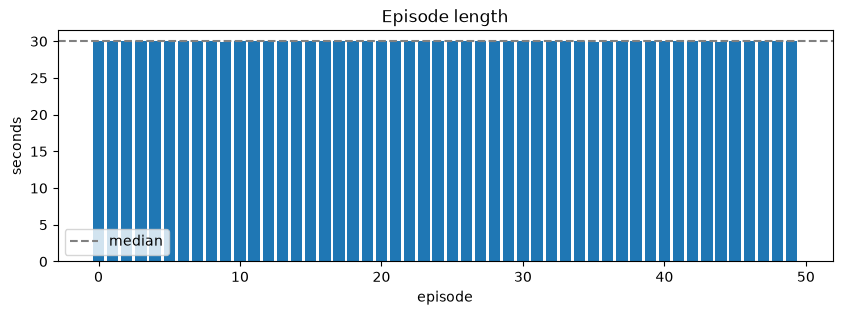

길이 이상 의심 에피소드: 없음


In [5]:
# 에피소드 길이 그래프 — 중앙값의 0.5배 미만(빨강)이나 2배 초과(주황)는 잘리거나 머뭇거린 시연일 수 있으니 우선 검수
if lengths is not None:
    color_map = {"짧음": "tab:red", "김": "tab:orange", "": "tab:blue"}
    plt.figure(figsize=(10, 3))
    plt.bar(lengths["episode_index"], lengths["seconds"], color=lengths["flag"].map(color_map))
    plt.axhline(lengths["seconds"].median(), ls="--", c="gray", label="median")
    plt.xlabel("episode"); plt.ylabel("seconds"); plt.title("Episode length")
    plt.legend(); plt.show()

    flagged = lengths[lengths["flag"] != ""]
    print("길이 이상 의심 에피소드:", flagged["episode_index"].tolist() or "없음")

## 3. 검수

### 3-1. 에피소드별 검수표
촬영 후 50개 에피소드의 영상을 모두 다시 확인했다. 대부분의 에피소드에서 정한 시나리오를 성공적으로 수행했으며, 일부에서는 물체가 미끄러워 집기에 실패했다. 실패한 에피소드의 번호와 정확한 개수는 다시 확인할 필요가 있다.
아래 표의 메모는 AI 보조 도구의 장면 추출 검토를 통해 추가한 참고 기록이며, 직접 확인한 최종 판정과 구분했다.
리뷰 메모는 시나리오 수행 중 확인한 접근·이동·자세 변화 중심으로 작성했다. 물체가 카메라 가까이 보이거나 시야가 일부 가려지는 장면 자체를 실패로 판단하지 않았다. 기존 O/X는 유지하고, 미판정 항목은 검수 미통과로 표시했다.

### 별도 검증 결과 — 자동 검사 및 AI 장면 추출 검토
다음 내용은 실습 중 직접 수행한 작업이나 개인 소감이 아니라, 보고서 작성 과정에서 AI 보조 도구로 확인한 결과이다.

- 대상: `yhks/my_task`의 커밋 `9837af86d698eb2408a58255dd152ff7d1ef36a6`.
- Hub의 데이터 파일 10개를 로컬 원본과 대조했으며, 대용량 파일의 SHA-256이 일치했다.
- 데이터는 0~49번 50개, 총 44,947프레임이고 에피소드별 행 수와 메타데이터 길이가 일치했다.
- 모든 에피소드에서 state/action 값이 유한하며, 6개 관절 각각의 변화가 확인됐다.
- MP4를 끝까지 디코딩한 결과 두 카메라 각각 44,947프레임, 합계 89,894프레임이 읽혔다. 디코딩 오류와 평균 밝기 2/255 미만의 프레임은 없었다.
- 48×36 축소 회색조 비교에서 연속 동일 프레임은 overhead 3,745회, wrist 3,934회였다. 정지 장면도 포함될 수 있어 이 수치만으로 영상 멈춤을 판정하지 않았다.
- 각 에피소드의 두 카메라에서 0·3·6·9·12·15·18·21·24·29초 장면 1,000장을 추출해 검토했다. 일부 구간에서 물체·로봇에 의한 시야 가림을 확인했다.

위 장면 추출 검토는 50개 영상을 연속 시청한 검수와 구분된다. 추출 시점 사이의 낙하, 짧은 끊김, 넣기·꺼내기의 완주 여부는 이 결과만으로 확정하지 않았다.

### 판정 기호
O는 기존에 성공으로 입력한 항목이며, X는 검수 미통과 항목이다. 이번에 ?에서 X로 바꾼 항목은 성공 여부 재확인이 필요하다는 뜻이며 실제 집기 실패를 확정한 판정이 아니다. 해당 항목은 메모에 구분해 표시했다.


In [ ]:
REVIEW = """
 0 | O | 본드 용기에 접근해 작업 위치로 이동했다.
 1 | O | 본드 용기에 접근한 뒤 젤콤 포장물 쪽으로 동작을 이어갔다.
 2 | X | 본드 용기 가까이에서 그리퍼의 작업 자세를 조절했다.
 3 | O | 용기에 접근한 상태에서 자세를 바꾸며 작업 동작을 이어갔다.
 4 | O | 후반부에 본드 용기 쪽으로 접근 동작을 수행했다.
 5 | O | 본드 용기와 포장물 주변에서 작업 위치와 자세를 바꿨다.
 6 | X | 본드 용기 쪽으로 접근한 뒤 그리퍼 자세를 조절했다.
 7 | X | 젤콤 포장물에 접근해 작업 동작을 수행했다.
 8 | X | 중반부 용기에서 후반부 포장물 쪽으로 작업 위치를 옮겼다.
 9 | O | 젤콤 포장물 가까이에서 자세를 바꾸며 작업 동작을 이어갔다.
10 | X | 본드 용기·젤콤 포장물·상자 주변으로 작업 위치를 옮겼다. [성공 여부 재확인 필요; 실패 확정 아님]
11 | X | 후반부에 본드 용기 가까이로 그리퍼를 이동했다. [성공 여부 재확인 필요; 실패 확정 아님]
12 | X | 젤콤 포장물 가까이에서 작업 동작을 수행했다. [성공 여부 재확인 필요; 실패 확정 아님]
13 | X | 포장물에 접근한 뒤 본드 용기 쪽으로 이동했다. [성공 여부 재확인 필요; 실패 확정 아님]
14 | X | 중반부 본드 용기에서 후반부 젤콤 포장물 쪽으로 이동했다. [성공 여부 재확인 필요; 실패 확정 아님]
15 | X | 젤콤 포장물 가까이에서 작업 자세를 조절했다. [성공 여부 재확인 필요; 실패 확정 아님]
16 | X | 본드 용기와 포장물 주변에서 접근 동작과 자세 변화를 반복했다. [성공 여부 재확인 필요; 실패 확정 아님]
17 | X | 기울어진 용기와 포장물이 놓인 배치에서 본드 용기에 접근했다. [성공 여부 재확인 필요; 실패 확정 아님]
18 | X | 본드 용기에 접근한 뒤 후반부에 포장물 쪽으로 이동했다. [성공 여부 재확인 필요; 실패 확정 아님]
19 | X | 후반부에 젤콤 포장물 쪽으로 접근했다. [성공 여부 재확인 필요; 실패 확정 아님]
20 | X | 본드 용기와 포장물 주변에서 움직이며 물체의 방향 변화가 나타났다. [성공 여부 재확인 필요; 실패 확정 아님]
21 | X | 후반부에 젤콤 포장물 가까이에서 동작을 이어갔다. [성공 여부 재확인 필요; 실패 확정 아님]
22 | X | 중반부 용기에 접근한 뒤 후반부 포장물 쪽으로 이동했다. [성공 여부 재확인 필요; 실패 확정 아님]
23 | X | 본드 용기와 포장물 가까이에서 작업 자세를 바꿨다. [성공 여부 재확인 필요; 실패 확정 아님]
24 | X | 후반부에 본드 용기 가까이 접근하는 동작을 수행했다. [성공 여부 재확인 필요; 실패 확정 아님]
25 | X | 젤콤 포장물과 본드 용기 주변에 접근했다. [성공 여부 재확인 필요; 실패 확정 아님]
26 | X | 중후반부에 용기와 포장물 주변에서 작업 동작을 이어갔다. [성공 여부 재확인 필요; 실패 확정 아님]
27 | X | 용기와 포장물 주변에서 접근 동작과 그리퍼 자세를 조절했다. [성공 여부 재확인 필요; 실패 확정 아님]
28 | X | 중반부 본드 용기에서 후반부 젤콤 포장물 쪽으로 이동했다. [성공 여부 재확인 필요; 실패 확정 아님]
29 | X | 초반 대기 후 본드 용기와 포장물 쪽으로 접근했다. [성공 여부 재확인 필요; 실패 확정 아님]
30 | X | 용기·포장물·상자 주변에서 작업 위치를 바꿨다. [성공 여부 재확인 필요; 실패 확정 아님]
31 | X | 본드 용기와 상자 주변으로 그리퍼를 이동했다. [성공 여부 재확인 필요; 실패 확정 아님]
32 | X | 본드 용기 가까이에서 그리퍼의 작업 자세를 조절했다. [성공 여부 재확인 필요; 실패 확정 아님]
33 | X | 후반부에 본드 용기와 젤콤 포장물 쪽으로 접근했다. [성공 여부 재확인 필요; 실패 확정 아님]
34 | X | 상자와 젤콤 포장물 주변에서 작업 자세를 바꿨다. [성공 여부 재확인 필요; 실패 확정 아님]
35 | X | 젤콤 포장물에서 본드 용기로 접근 대상을 바꿨다. [성공 여부 재확인 필요; 실패 확정 아님]
36 | X | 초반 대기 후 중반부에 본드 용기 쪽으로 접근했다. [성공 여부 재확인 필요; 실패 확정 아님]
37 | X | 본드 용기에 접근한 뒤 젤콤 포장물 쪽으로 이동했다. [성공 여부 재확인 필요; 실패 확정 아님]
38 | X | 중반부 본드 용기 가까이에서 그리퍼 자세를 조절했다. [성공 여부 재확인 필요; 실패 확정 아님]
39 | X | 포장물과 본드 용기에 접근한 뒤 상자 주변으로 이동했다. [성공 여부 재확인 필요; 실패 확정 아님]
40 | X | 용기와 포장물 주변에서 동작했으며, 종료 시 용기가 누운 상태였다. [성공 여부 재확인 필요; 실패 확정 아님]
41 | X | 초반 대기 후 본드 용기 가까이에서 동작을 이어갔다. [성공 여부 재확인 필요; 실패 확정 아님]
42 | X | 용기 가까이에서 시작해 후반부 상자와 포장물 쪽으로 이동했다. [성공 여부 재확인 필요; 실패 확정 아님]
43 | X | 초반 용기·포장물 주변에서 동작한 뒤 후반부 본드 용기에 접근했다. [성공 여부 재확인 필요; 실패 확정 아님]
44 | X | 중후반부에 본드 용기 가까이에서 작업 동작을 수행했다. [성공 여부 재확인 필요; 실패 확정 아님]
45 | X | 초반 대기 후 후반부에 젤콤 포장물 쪽으로 접근했다. [성공 여부 재확인 필요; 실패 확정 아님]
46 | X | 용기·상자·포장물 주변에서 작업 위치를 바꿨다. [성공 여부 재확인 필요; 실패 확정 아님]
47 | X | 본드 용기에 접근한 뒤 젤콤 포장물 쪽으로 이동했다. [성공 여부 재확인 필요; 실패 확정 아님]
48 | X | 중반부 포장물에 접근한 뒤 후반부 본드 용기에 접근했다. [성공 여부 재확인 필요; 실패 확정 아님]
49 | X | 마지막 에피소드로 로봇의 물체 조작 시연을 기록했다. [성공 여부 재확인 필요; 실패 확정 아님]
"""

review_rows = []
for line in REVIEW.strip().splitlines():
    parts = [p.strip() for p in line.split("|")]
    review_rows.append({"episode": int(parts[0]), "result": parts[1],
                        "note": parts[2] if len(parts) > 2 else ""})
review_df = pd.DataFrame(review_rows)
print(review_df["result"].value_counts().to_string())
review_df[review_df["result"] != "O"]   # O가 아닌 행만 표시

### 3-2. 재녹화 기록

39번과 46번 에피소드에서는 물체를 잡는 동작 자체가 완전히 실패했다. 실패한 시연을 그대로 저장하지 않기 위해 수집을 중단하고, 왼쪽 화살표로 해당 에피소드를 취소한 뒤 다시 촬영했다. 이는 녹화 도중의 재촬영 기록이며, 최종 50개를 재생하면서 발견한 문제 에피소드와는 별도로 구분했다.

49번 에피소드 저장과 영상 인코딩을 마친 뒤 프로그램을 종료하는 과정에서 모터 id 6의 토크 해제에 Overload 오류가 발생했다. 보고서 작성 과정의 별도 자동 검사에서는 50개 에피소드의 메타데이터와 프레임 데이터가 일치했다.


## 4. 소감 및 과제 2 준비

**4-1. 수집하면서 시연의 일관성을 유지하기 위해 신경 쓴 점**

넣기와 꺼내기를 한 가지 동작으로만 반복하지 않고, 두 물체를 모두 다루는 경우와 하나씩 다루는 경우, 박스 안에서 시작하는 경우를 나누어 촬영했다.
각 시나리오를 그리퍼 각도를 세로로 한 자세에서도 수행하도록 했으며, 물체를 잡는 행동 자체가 완전히 실패한 경우에는 수집을 중단하고 다시 촬영했다.

**4-2. ACT 학습 시 예상되는 어려움**

이번 태스크는 본드 용기와 젤콤 종이박스를 잡아 빈 박스에 넣고 다시 꺼내는 작업이므로, 물체의 모양과 놓인 방향에 따라 잡는 위치와 그리퍼 자세를 다르게 맞춰야 한다고 생각한다.
실제로 물체가 미끄러워 집기에 실패한 경우가 있었으므로, ACT도 물체의 모양과 방향에 맞게 잡는 위치를 조절하고 안정적으로 유지하는 데 어려움을 겪을 수 있다고 생각한다.
그리퍼 각도를 세로로 한 자세에서도 이 작업을 수행하도록 시연을 구성했으므로, 이후 학습 결과에서 여러 시작 상태와 자세에 따라 넣기·꺼내기 동작을 적절히 선택하는지 확인하고자 한다.


## 제출 전 체크리스트
아래 셀을 실행해 모든 항목이 통과하는지 확인한 뒤 커밋한다.

In [ ]:
check_items = {
    "데이터셋 접근 가능 (public)": len(repo_files) > 0,
    "에피소드 50개": bool(info) and info.get("total_episodes") == 50,
    "검수표 50개 에피소드 모두 기재": sorted(review_df["episode"]) == list(range(50)),
    "검수 결과 모두 O": (review_df["result"] == "O").all(),
    "태스크 문장이 TASK와 일치하고 영어로 작성됨": task_set == {TASK} and all(t.isascii() for t in task_set),
    "검수표와 데이터셋 에피소드 수 일치": bool(info) and len(review_df) == info.get("total_episodes"),
}
for k, v in check_items.items():
    print(("[통과] " if v else "[미흡] ") + k)
print("\n모두 통과" if all(check_items.values()) else "\n미흡 항목을 보완한 뒤 커밋할 것")